# IBM Stock Price Forecasting with ARIMA, SARIMA, and SARIMAX
  
**Dataset:** `Data/IBM_2006_to_2018.csv`  
**Target:** IBM month-end `Close` price  
**Raw cadence:** trading sessions from 2006-01-03 to 2017-12-29  
**Forecast horizon:** 24 months



## 0) Setup


In [119]:
# %pip install -q pandas numpy matplotlib statsmodels scikit-learn scipy


In [120]:
from pathlib import Path
import itertools
import platform
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display, Markdown
except Exception:
    display = print
    Markdown = lambda text: text

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, acf, kpss

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
DATA_PATH = Path("Data/IBM_2006_to_2018.csv")
DATE_COL = "Date"
TARGET_COL = "Close"
VOLUME_COL = "Volume"
H = 24
SEASONAL_PERIOD = 12

COLORS = {
    "actual": "#1f77b4",
    "train": "#4C78A8",
    "test": "#F58518",
    "forecast": "#54A24B",
    "interval": "#A0CBE8",
    "baseline": "#B279A2",
    "diagnostic": "#E45756",
}

plt.rcParams.update({
    "figure.figsize": (11, 4),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

pd.Series({
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
}).to_frame("version")


,version
python,3.13.0
pandas,2.3.3
numpy,2.4.1


### Helper Functions

**What we are doing:** defining reusable functions for metrics, stationarity tests, differencing, confidence interval checks, and SARIMAX fitting.  
**Why it matters:** keeping these functions in one place makes every later step easier to audit and reproduce.


In [121]:
def smape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denom = np.abs(actual) + np.abs(predicted)
    out = np.where(denom == 0, 0.0, 2.0 * np.abs(predicted - actual) / denom)
    return float(np.mean(out) * 100)


def metric_row(actual, predicted, model_name):
    actual = pd.Series(actual).astype(float)
    predicted = pd.Series(predicted, index=actual.index).astype(float)
    err = actual - predicted
    return {
        "model": model_name,
        "MAE": float(np.mean(np.abs(err))),
        "RMSE": float(np.sqrt(np.mean(err ** 2))),
        "sMAPE_%": smape(actual, predicted),
        "Bias": float(np.mean(predicted - actual)),
    }


def unit_root_report(series, name):
    clean = pd.Series(series).dropna().astype(float)
    result = {"series": name, "n": len(clean)}
    if len(clean) < 20 or clean.nunique() < 3:
        result.update({"ADF_stat": np.nan, "ADF_p": np.nan, "KPSS_stat": np.nan, "KPSS_p": np.nan})
        return result

    adf_result = adfuller(clean, autolag="AIC")
    result.update({
        "ADF_stat": adf_result[0],
        "ADF_p": adf_result[1],
        "ADF_lags": adf_result[2],
        "ADF_5pct_crit": adf_result[4]["5%"],
    })
    try:
        kpss_result = kpss(clean, regression="c", nlags="auto")
        result.update({
            "KPSS_stat": kpss_result[0],
            "KPSS_p": kpss_result[1],
            "KPSS_lags": kpss_result[2],
            "KPSS_5pct_crit": kpss_result[3]["5%"],
        })
    except Exception as exc:
        result.update({"KPSS_stat": np.nan, "KPSS_p": np.nan, "KPSS_lags": np.nan, "KPSS_5pct_crit": np.nan})
        print(f"KPSS failed for {name}: {exc}")
    return result


def difference_series(series, d=0, D=0, m=12):
    out = pd.Series(series).copy()
    for _ in range(D):
        out = out.diff(m)
    for _ in range(d):
        out = out.diff()
    return out.dropna()


def acf_numeric_table(series, nlags=12):
    clean = pd.Series(series).dropna().astype(float)
    max_lag = min(nlags, len(clean) - 2)
    values, confint = acf(clean, nlags=max_lag, alpha=0.05, fft=False)
    rows = []
    for lag in range(1, max_lag + 1):
        rows.append({
            "lag": lag,
            "acf": values[lag],
            "ci_low": confint[lag, 0],
            "ci_high": confint[lag, 1],
            "significant_95pct": not (confint[lag, 0] <= 0 <= confint[lag, 1]),
        })
    return pd.DataFrame(rows)


def forecast_to_price(forecast_result):
    mean_log = forecast_result.predicted_mean
    ci_log = forecast_result.conf_int(alpha=0.05)
    return pd.DataFrame({
        "forecast": np.exp(mean_log),
        "lower_95": np.exp(ci_log.iloc[:, 0]),
        "upper_95": np.exp(ci_log.iloc[:, 1]),
    })


def fit_sarimax_safe(y, order, seasonal_order=(0, 0, 0, 0), exog=None):
    return SARIMAX(
        y,
        order=order,
        seasonal_order=seasonal_order,
        exog=exog,
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False, maxiter=250)


## 1) Load the Data

Reading the CSV and previewing the raw structure.  
Before modeling, we need to confirm column names, target values, date format, and missingness.  


In [122]:
raw = pd.read_csv(DATA_PATH)
print(f"Raw shape: {raw.shape}")
display(raw.head())
display(raw.tail())
display(raw.dtypes.to_frame("dtype"))


Raw shape: (3020, 7)


,Date,Open,High,Low,Close,Volume,Name
0,2006-01-03,82.45,82.55,80.81,82.06,11715200,IBM
1,2006-01-04,82.20,82.50,81.33,81.95,9840600,IBM
2,2006-01-05,81.40,82.90,81.00,82.50,7213500,IBM
3,2006-01-06,83.95,85.03,83.41,84.95,8197400,IBM
4,2006-01-09,84.10,84.25,83.38,83.73,6858200,IBM


,Date,Open,High,Low,Close,Volume,Name
3015,2017-12-22,151.82,153.00,151.50,152.50,2990583,IBM
3016,2017-12-26,152.51,153.86,152.50,152.83,2479017,IBM
3017,2017-12-27,152.95,153.18,152.61,153.13,2149257,IBM
3018,2017-12-28,153.20,154.12,153.20,154.04,2687624,IBM
3019,2017-12-29,154.17,154.72,153.42,153.42,3327087,IBM


,dtype
Date,object
Open,float64
High,float64
Low,float64
Close,float64
Volume,int64
Name,object


### Timestamp Validation

Parsing dates, checking duplicates, monotonic order, weekends, and timezone localization edge cases.  
Time-series models are only meaningful if the index is clean and ordered.  



In [123]:
required_cols = {DATE_COL, "Open", "High", "Low", TARGET_COL, VOLUME_COL, "Name"}
missing_required = sorted(required_cols - set(raw.columns))
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

parsed_date = pd.to_datetime(raw[DATE_COL], format="%Y-%m-%d", errors="coerce")
localized_for_validation = parsed_date.dt.tz_localize(
    "America/New_York",
    nonexistent="shift_forward",
    ambiguous="NaT",
)

timestamp_audit = pd.Series({
    "rows": len(raw),
    "parse_failures": int(parsed_date.isna().sum()),
    "timezone_validation_failures": int(localized_for_validation.isna().sum()),
    "duplicate_dates": int(parsed_date.duplicated().sum()),
    "monotonic_increasing": bool(parsed_date.is_monotonic_increasing),
    "weekend_rows": int(parsed_date.dt.dayofweek.isin([5, 6]).sum()),
    "first_date": parsed_date.min().date(),
    "last_date": parsed_date.max().date(),
})
display(timestamp_audit.to_frame("timestamp_audit"))


,timestamp_audit
rows,3020
parse_failures,0
timezone_validation_failures,0
duplicate_dates,0
monotonic_increasing,True
weekend_rows,0
first_date,2006-01-03
last_date,2017-12-29


### Clean Required Fields

Coercing price/volume fields to numeric values, dropping rows that cannot support the target, and creating a date index.  
This is important because ARIMA-family models require an ordered numeric series.


In [124]:
for col in ["Open", "High", "Low", TARGET_COL, VOLUME_COL]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

clean = (
    raw.assign(Date=parsed_date)
        .dropna(subset=["Date", TARGET_COL, VOLUME_COL])
        .sort_values("Date")
        .drop_duplicates(subset="Date", keep="last")
        .set_index("Date")
)

business_index = pd.date_range(clean.index.min(), clean.index.max(), freq="B")
missing_business_dates = business_index.difference(clean.index)
gaps = clean.index.to_series().diff().dt.days.dropna()

data_quality = pd.DataFrame({
    "metric": [
        "valid_rows_after_required_target_cleaning",
        "missing_business_days_between_first_and_last",
        "median_observed_gap_days",
        "max_observed_gap_days",
        "missing_open_values",
        "missing_low_values",
        "missing_close_values",
    ],
    "value": [
        len(clean),
        len(missing_business_dates),
        gaps.median(),
        gaps.max(),
        clean["Open"].isna().sum(),
        clean["Low"].isna().sum(),
        clean[TARGET_COL].isna().sum(),
    ],
})
display(data_quality)
display(clean.head())


,metric,value
0,valid_rows_after_required_target_cleaning,3020.0
1,missing_business_days_between_first_and_last,109.0
2,median_observed_gap_days,1.0
3,max_observed_gap_days,5.0
4,missing_open_values,1.0
5,missing_low_values,1.0
6,missing_close_values,0.0


,Open,High,Low,Close,Volume,Name
Date,,,,,,
2006-01-03,82.45,82.55,80.81,82.06,11715200,IBM
2006-01-04,82.20,82.50,81.33,81.95,9840600,IBM
2006-01-05,81.40,82.90,81.00,82.50,7213500,IBM
2006-01-06,83.95,85.03,83.41,84.95,8197400,IBM
2006-01-09,84.10,84.25,83.38,83.73,6858200,IBM


Missing business dates are expected in a stock-market dataset because weekends and exchange holidays are not trading sessions. We should not blindly fill the raw daily target before deciding the modeling frequency.


This file contains date-only stock-market records rather than intraday timestamps, so daylight-saving ambiguity is unlikely in practice. I still localize the parsed dates to `America/New_York` as a robustness check because IBM trades on a New York exchange calendar and reproducible timestamp handling should make timezone assumptions explicit.


## 2) Compare Frequency Choices

Comparing trading-session, business-day, weekly, and monthly versions of IBM close.  
The aggregation rule changes the signal.


In [125]:
daily_close = clean[TARGET_COL].astype(float).rename("daily_trading_close")
business_close = daily_close.asfreq("B").ffill().rename("business_day_ffill_close")
weekly_close = daily_close.resample("W-FRI").last().dropna().rename("weekly_friday_close")
monthly_close = daily_close.resample("ME").last().dropna().rename("monthly_month_end_close")
monthly_close.index.freq = "ME"

candidate_series = {
    "trading_session": (daily_close, 252),
    "business_day_ffill": (business_close, 252),
    "weekly_friday_last": (weekly_close, 52),
    "monthly_end_last": (monthly_close, 12),
}


In [126]:
rows = []
for name, (series, periods_per_year) in candidate_series.items():
    log_returns = np.log(series).diff().dropna()
    try:
        stl_fit = STL(series.dropna(), period=min(periods_per_year, max(2, len(series) // 3)), robust=True).fit()
        remainder_var = np.nanvar(stl_fit.resid)
        seasonal_remainder_var = np.nanvar(stl_fit.seasonal + stl_fit.resid)
        seasonal_strength = max(0, 1 - remainder_var / seasonal_remainder_var) if seasonal_remainder_var > 0 else np.nan
    except Exception:
        seasonal_strength = np.nan
    rows.append({
        "candidate": name,
        "observations": int(series.dropna().shape[0]),
        "missing_values": int(series.isna().sum()),
        "periods_per_year": periods_per_year,
        "annualized_log_return_vol": float(log_returns.std(ddof=1) * np.sqrt(periods_per_year)),
        "lag1_log_return_acf": float(log_returns.autocorr(lag=1)),
        "stl_seasonal_strength": seasonal_strength,
    })

resampling_comparison = pd.DataFrame(rows).set_index("candidate")
display(resampling_comparison.round(4))


,observations,missing_values,periods_per_year,annualized_log_return_vol,lag1_log_return_acf,stl_seasonal_strength
candidate,,,,,,
trading_session,3020,0,252,0.2148,-0.0114,0.0289
business_day_ffill,3129,0,252,0.2110,-0.0123,0.0917
weekly_friday_last,626,0,52,0.2166,-0.1162,0.0460
monthly_end_last,144,0,12,0.1838,0.0461,0.0000


### Resampling Trade-Off Interpretation

Turning the comparison table into a direct modeling decision.  
Monthly aggregation loses short-term information, so we need to justify why that loss is acceptable for a medium-term forecasting task.


In [127]:
daily_vol = resampling_comparison.loc["trading_session", "annualized_log_return_vol"]
monthly_vol = resampling_comparison.loc["monthly_end_last", "annualized_log_return_vol"]
vol_change = (monthly_vol - daily_vol) / daily_vol * 100
monthly_seasonal_strength = resampling_comparison.loc["monthly_end_last", "stl_seasonal_strength"]

print(round(daily_vol, 4))
print(round(monthly_vol, 4))
print(round(vol_change, 1))
print(round(monthly_seasonal_strength, 4))


0.2148
0.1838
-14.4
0.0


- Monthly aggregation changes annualized log-return volatility from 0.2148 to 0.1838, a -14.4% change versus the raw trading-session series.
- The monthly STL seasonal-strength estimate is 0.0000, so seasonal terms should be tested but not assumed to dominate the model.
- For our current scope, the interpretability of an investable month-end price and the improved signal-to-noise ratio for medium-term planning outweigh the loss of daily tactical detail.

### Choose the Modeling Series

We will use month-end close.  
For a medium-term forecast, month-end close is an interpretable investable endpoint, reduces daily market noise, avoids artificial holiday forward-filling in the target, and gives a transparent seasonal period of `m = 12`.


In [128]:
selected_series = monthly_close.copy()
selected_series.name = "IBM_month_end_close"
ts = selected_series.asfreq("ME")
log_ts = np.log(ts).rename("log_month_end_close")

print(f"Selected series: {selected_series.name}")
print(f"Observations: {len(ts)}")
print(f"Frequency: {ts.index.freqstr}")
print(f"Missing months after aggregation: {ts.isna().sum()}")


Selected series: IBM_month_end_close
Observations: 144
Frequency: ME
Missing months after aggregation: 0


## 3) Explore the Series

Looking at the series before modeling.  
Trend, volatility, seasonality, and structural breaks influence transformation and model choice.  

In [129]:
summary = ts.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame("IBM close")
summary.loc["start"] = ts.index.min()
summary.loc["end"] = ts.index.max()
display(summary)


,IBM close
count,144.0
mean,146.019028
std,37.456838
min,76.82
5%,82.0
25%,117.59
50%,151.615
75%,179.3275
95%,200.215
max,213.3


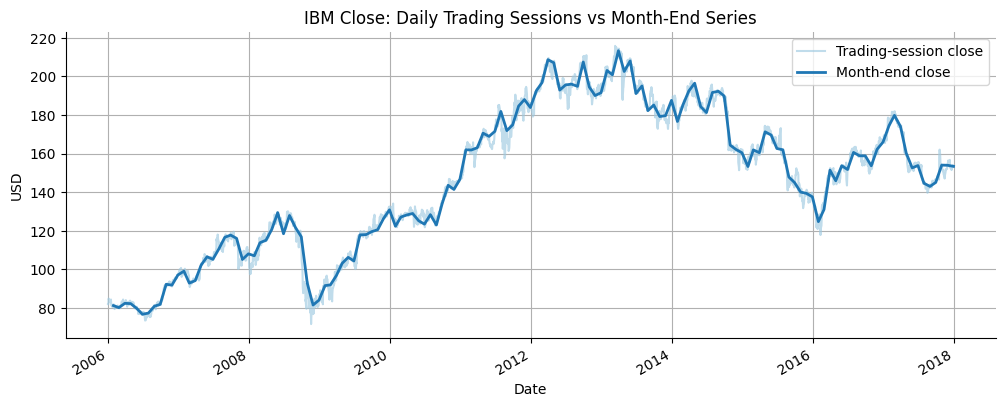

In [130]:
fig, ax = plt.subplots(figsize=(12, 4.5))
daily_close.plot(ax=ax, color="#9ecae1", alpha=0.65, label="Trading-session close")
ts.plot(ax=ax, color=COLORS["actual"], lw=2.0, label="Month-end close")
ax.set_title("IBM Close: Daily Trading Sessions vs Month-End Series")
ax.set_ylabel("USD")
ax.legend()
plt.show()


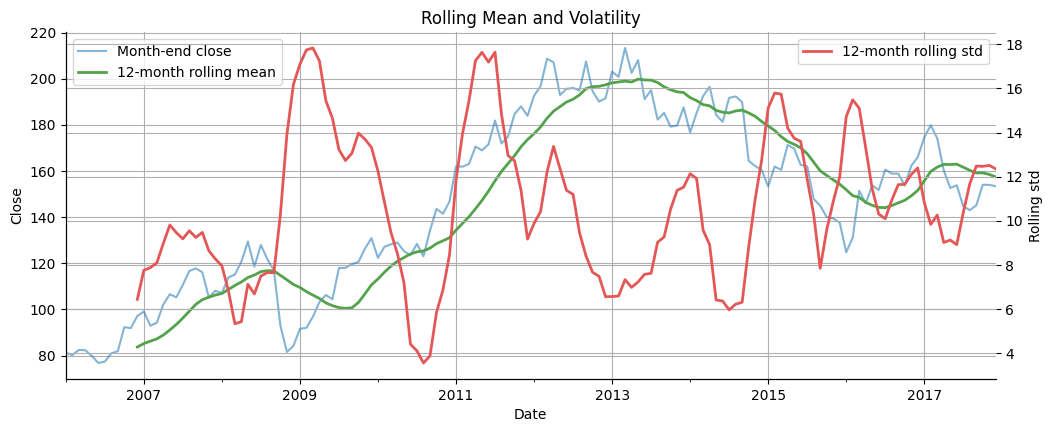

In [131]:
rolling = ts.rolling(12)
fig, ax = plt.subplots(figsize=(12, 4.5))
ts.plot(ax=ax, color=COLORS["actual"], alpha=0.55, label="Month-end close")
rolling.mean().plot(ax=ax, color=COLORS["forecast"], lw=2, label="12-month rolling mean")
std_ax = ax.twinx()
rolling.std().plot(ax=std_ax, color=COLORS["diagnostic"], lw=2, label="12-month rolling std")
ax.set_title("Rolling Mean and Volatility")
ax.set_ylabel("Close")
std_ax.set_ylabel("Rolling std")
ax.legend(loc="upper left")
std_ax.legend(loc="upper right")
plt.show()


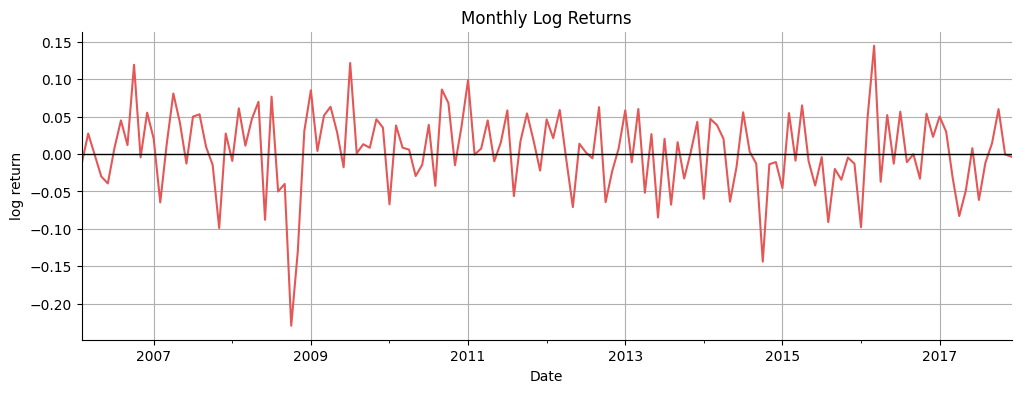

In [132]:
monthly_returns = log_ts.diff().dropna()
fig, ax = plt.subplots(figsize=(12, 4))
monthly_returns.plot(ax=ax, color=COLORS["diagnostic"], lw=1.5)
ax.axhline(0, color="black", lw=1)
ax.set_title("Monthly Log Returns")
ax.set_ylabel("log return")
plt.show()


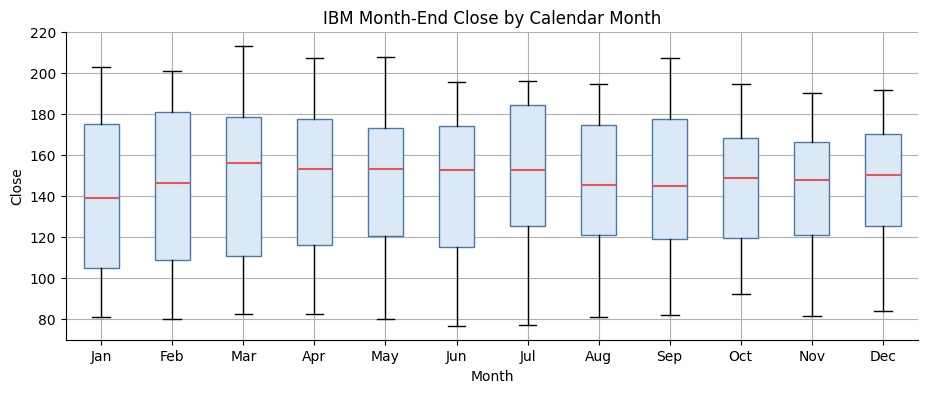

In [133]:
month_order = pd.date_range("2000-01-31", periods=12, freq="ME").month_name().str[:3]
month_values = [ts[ts.index.month == month].values for month in range(1, 13)]
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(month_values, labels=month_order, patch_artist=True,
           boxprops={"facecolor": "#dbe9f6", "edgecolor": "#4C78A8"},
           medianprops={"color": COLORS["diagnostic"], "linewidth": 1.5})
ax.set_title("IBM Month-End Close by Calendar Month")
ax.set_xlabel("Month")
ax.set_ylabel("Close")
plt.show()


At this stage we should expect non-stationarity because IBM prices move through multi-year regimes. The return plot is usually more stable than the price level, which hints that log transformation and differencing will be useful.


### Market Context Behind the Exploratory Patterns

IBM is a mature technology company, so its stock does not behave like a purely seasonal consumer-demand series. The 2008-2009 financial crisis, the post-2013 growth slowdown, broad market risk cycles, earnings surprises, and strategic shifts toward cloud and services can all create level shifts and volatility clusters. This context matters because ARIMA-family models can capture persistence and mean dynamics, but they cannot fully explain structural business changes unless relevant external variables are added.


## 4) Decompose Trend and Seasonality

Separating log price into trend, seasonal, and residual components with STL.  
Decomposition gives visual and quantitative evidence about seasonal structure before we fit SARIMA.  


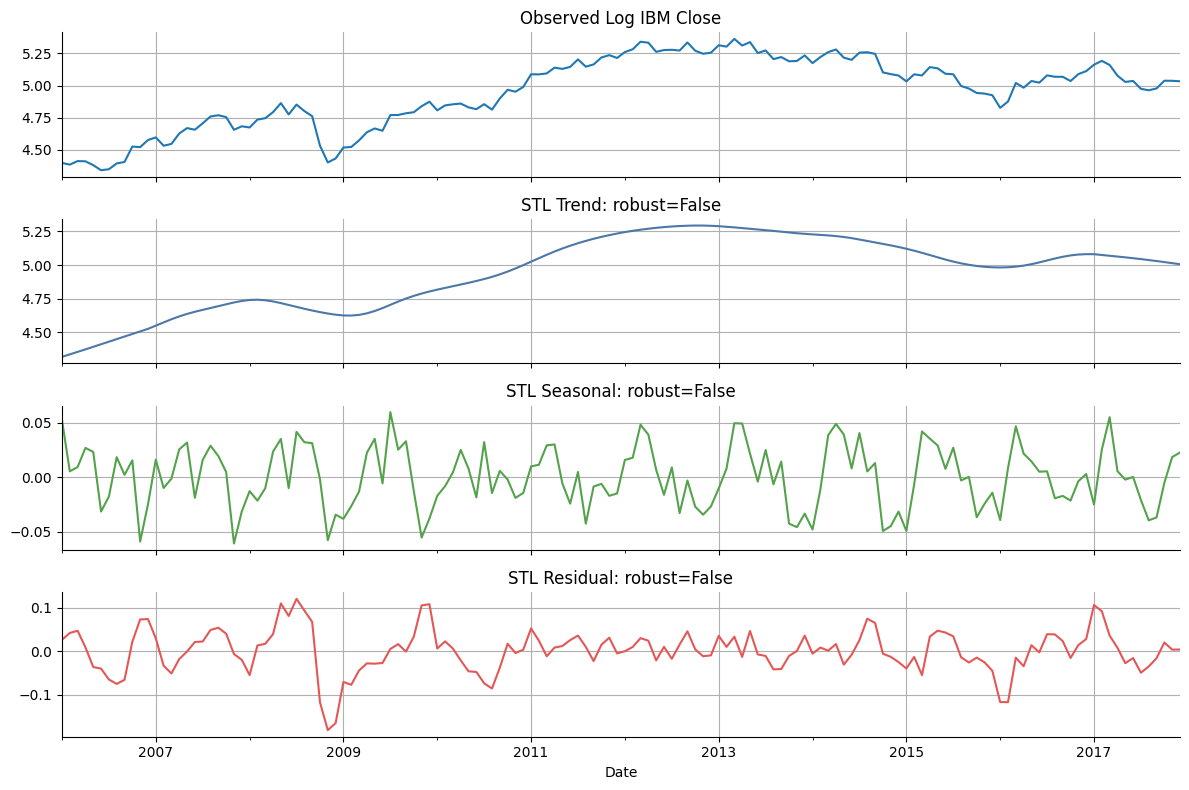

In [134]:
stl_standard = STL(log_ts, period=SEASONAL_PERIOD, robust=False).fit()

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
log_ts.plot(ax=axes[0], color=COLORS["actual"])
axes[0].set_title("Observed Log IBM Close")
stl_standard.trend.plot(ax=axes[1], color=COLORS["train"])
axes[1].set_title("STL Trend: robust=False")
stl_standard.seasonal.plot(ax=axes[2], color=COLORS["forecast"])
axes[2].set_title("STL Seasonal: robust=False")
stl_standard.resid.plot(ax=axes[3], color=COLORS["diagnostic"])
axes[3].set_title("STL Residual: robust=False")
plt.tight_layout()
plt.show()


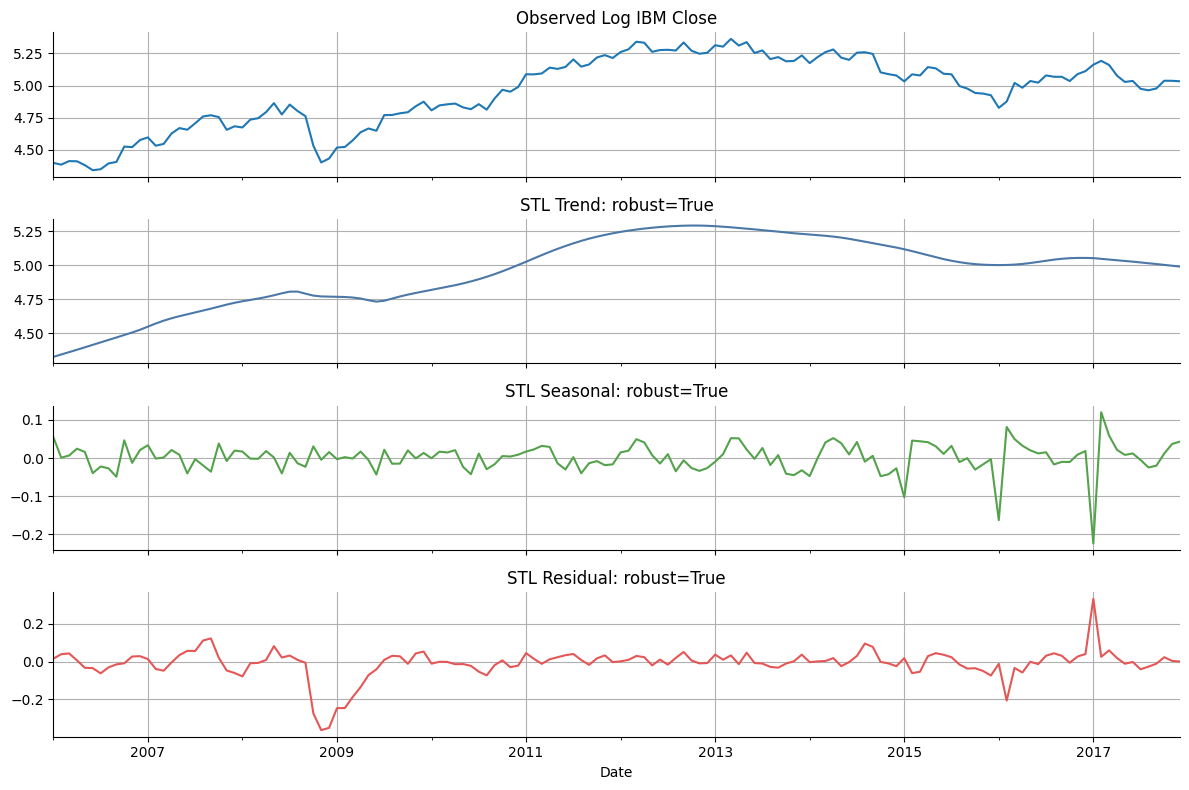

In [135]:
stl_robust = STL(log_ts, period=SEASONAL_PERIOD, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
log_ts.plot(ax=axes[0], color=COLORS["actual"])
axes[0].set_title("Observed Log IBM Close")
stl_robust.trend.plot(ax=axes[1], color=COLORS["train"])
axes[1].set_title("STL Trend: robust=True")
stl_robust.seasonal.plot(ax=axes[2], color=COLORS["forecast"])
axes[2].set_title("STL Seasonal: robust=True")
stl_robust.resid.plot(ax=axes[3], color=COLORS["diagnostic"])
axes[3].set_title("STL Residual: robust=True")
plt.tight_layout()
plt.show()


In [136]:
seasonal_strength = 1 - np.nanvar(stl_robust.resid) / np.nanvar(stl_robust.seasonal + stl_robust.resid)
trend_strength = 1 - np.nanvar(stl_robust.resid) / np.nanvar(stl_robust.trend + stl_robust.resid)

decomp_strength = pd.Series({
    "trend_strength_robust_stl": max(0, trend_strength),
    "seasonal_strength_robust_stl": max(0, seasonal_strength),
    "residual_std_log_units": stl_robust.resid.std(ddof=1),
})
display(decomp_strength.to_frame("value").round(4))


,value
trend_strength_robust_stl,0.9239
seasonal_strength_robust_stl,0.0156
residual_std_log_units,0.0763


If trend strength is high, differencing is likely needed. If seasonal strength is weak, SARIMA may still be tested, but the final selection should depend on AIC/BIC, holdout metrics, cross-validation, and residual diagnostics.


## 5) Transformation Diagnostics

Comparing price level, log price, first differences, log returns, seasonal differences, and combined differences.  
ARIMA assumes a stationary working series after differencing.  
ADF p-value below 0.05 supports stationarity; KPSS p-value above 0.05 supports stationarity.


In [137]:
transform_candidates = {
    "price_level": ts,
    "log_price_level": log_ts,
    "price_first_diff": ts.diff(),
    "log_first_diff_return": log_ts.diff(),
    "log_seasonal_diff_12": log_ts.diff(SEASONAL_PERIOD),
    "log_regular_plus_seasonal_diff": log_ts.diff(SEASONAL_PERIOD).diff(),
}

transform_rows = []
for name, series in transform_candidates.items():
    clean_series = pd.Series(series).dropna()
    report = unit_root_report(clean_series, name)
    report.update({
        "variance": float(clean_series.var(ddof=1)),
        "skew": float(clean_series.skew()),
        "kurtosis": float(clean_series.kurtosis()),
        "rolling_cv_median": float((clean_series.rolling(12).std() / clean_series.rolling(12).mean().abs()).median()),
    })
    transform_rows.append(report)

transform_diagnostics = pd.DataFrame(transform_rows).set_index("series")
display(transform_diagnostics.round(5))


,n,ADF_stat,ADF_p,ADF_lags,ADF_5pct_crit,KPSS_stat,KPSS_p,KPSS_lags,KPSS_5pct_crit,variance,skew,kurtosis,rolling_cv_median
series,,,,,,,,,,,,,
price_level,144,-1.82413,0.36855,0,-2.88197,1.01733,0.01000,8,0.463,1403.01473,-0.14631,-1.09186,0.07098
log_price_level,144,-2.00942,0.28246,0,-2.88197,1.09930,0.01000,8,0.463,0.07629,-0.52703,-0.75698,0.01432
price_first_diff,143,-12.29972,0.00000,0,-2.88212,0.20924,0.10000,1,0.463,56.39201,-0.57962,0.95813,4.70923
log_first_diff_return,143,-11.30267,0.00000,0,-2.88212,0.21944,0.10000,1,0.463,0.00281,-0.72369,2.30487,4.74976
log_seasonal_diff_12,132,-1.73686,0.41223,12,-2.88615,0.52824,0.03531,6,0.463,0.03062,0.11767,-0.95641,0.71638
log_regular_plus_seasonal_diff,131,-5.04923,0.00002,11,-2.88615,0.03439,0.10000,2,0.463,0.00501,0.15150,1.00837,5.26277


Model log price, then let ARIMA/SARIMA differencing handle non-stationarity. This keeps forecasts positive after exponentiation and treats changes as approximately multiplicative, which is appropriate for stock prices.


## 6) Differencing, ACF, and PACF

Testing multiple `(d, D)` combinations and then inspecting correlation structure after the selected differencing.  
Too little differencing leaves trend; too much differencing adds unnecessary noise.  


In [138]:
diff_rows = []
for d in [0, 1, 2]:
    for D in [0, 1]:
        transformed = difference_series(log_ts, d=d, D=D, m=SEASONAL_PERIOD)
        report = unit_root_report(transformed, f"d={d}, D={D}")
        report.update({
            "d": d,
            "D": D,
            "variance": float(transformed.var(ddof=1)),
            "lag1_acf": float(transformed.autocorr(lag=1)),
            "abs_lag1_acf": float(abs(transformed.autocorr(lag=1))),
        })
        diff_rows.append(report)

differencing_table = pd.DataFrame(diff_rows).set_index(["d", "D"]).sort_index()
display(differencing_table.round(5))


series    n  ADF_stat    ADF_p  ADF_lags  ADF_5pct_crit  KPSS_stat  \
d D                                                                         
0 0  d=0, D=0  144  -2.00942  0.28246         0       -2.88197    1.09930   
  1  d=0, D=1  132  -1.73686  0.41223        12       -2.88615    0.52824   
1 0  d=1, D=0  143 -11.30267  0.00000         0       -2.88212    0.21944   
  1  d=1, D=1  131  -5.04923  0.00002        11       -2.88615    0.03439   
2 0  d=2, D=0  142  -5.53950  0.00000        13       -2.88440    0.17496   
  1  d=2, D=1  130  -4.94626  0.00003        12       -2.88658    0.10729   

      KPSS_p  KPSS_lags  KPSS_5pct_crit  variance  lag1_acf  abs_lag1_acf  
d D                                                                        
0 0  0.01000          8           0.463   0.07629   0.98151       0.98151  
  1  0.03531          6           0.463   0.03062   0.91839       0.91839  
1 0  0.10000          1           0.463   0.00281   0.04607       0.04607  
  1  0.10000          2           0.463   0.00501   0.09291       0.09291  
2 0  0.10000         48           0.463   0.00540  -0.50492       0.50492  
  1  0.10000         19           0.463   0.00914  -0.46076       0.46076

In [139]:
stationary_candidates = differencing_table[
    (differencing_table["ADF_p"] < 0.05) & (differencing_table["KPSS_p"] > 0.05)
].copy()

if len(stationary_candidates):
    selected_idx = stationary_candidates.assign(
        penalty=stationary_candidates.index.get_level_values("d") + 2 * stationary_candidates.index.get_level_values("D")
    ).sort_values(["penalty", "variance", "abs_lag1_acf"]).index[0]
else:
    selected_idx = differencing_table.sort_values(["ADF_p", "variance"]).index[0]

SELECTED_D = int(selected_idx[0])
SELECTED_SEASONAL_D = int(selected_idx[1])
stationary_view = difference_series(log_ts, d=SELECTED_D, D=SELECTED_SEASONAL_D, m=SEASONAL_PERIOD)

print(f"Selected differencing candidate: d={SELECTED_D}, D={SELECTED_SEASONAL_D}, m={SEASONAL_PERIOD}")


Selected differencing candidate: d=1, D=0, m=12


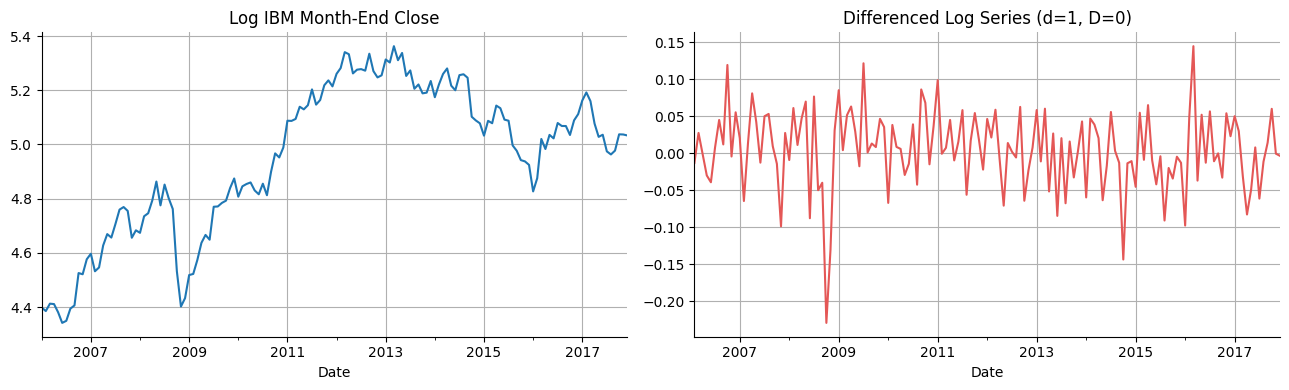

In [140]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
log_ts.plot(ax=axes[0], color=COLORS["actual"])
axes[0].set_title("Log IBM Month-End Close")
stationary_view.plot(ax=axes[1], color=COLORS["diagnostic"])
axes[1].set_title(f"Differenced Log Series (d={SELECTED_D}, D={SELECTED_SEASONAL_D})")
plt.tight_layout()
plt.show()


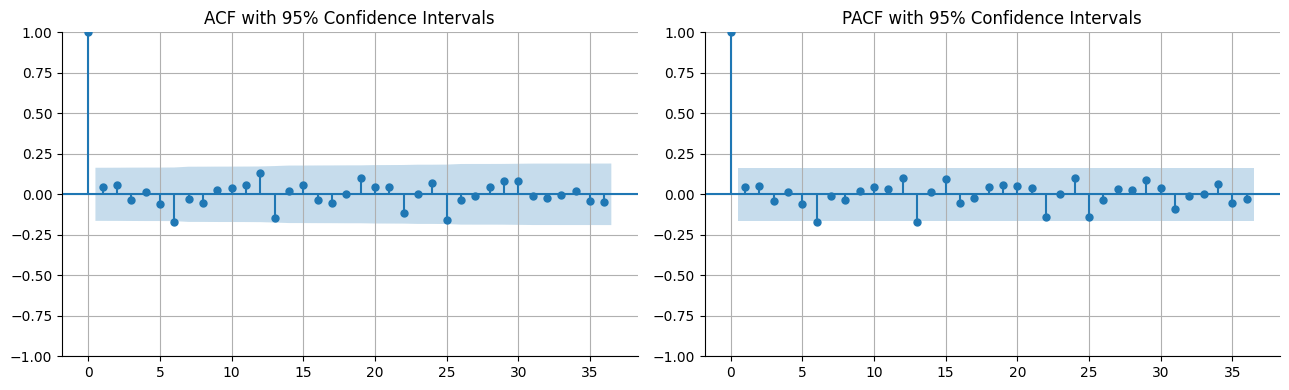

In [141]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
max_lags = min(36, len(stationary_view) // 2 - 1)
plot_acf(stationary_view, lags=max_lags, alpha=0.05, ax=axes[0])
axes[0].set_title("ACF with 95% Confidence Intervals")
plot_pacf(stationary_view, lags=max_lags, alpha=0.05, method="ywm", ax=axes[1])
axes[1].set_title("PACF with 95% Confidence Intervals")
plt.tight_layout()
plt.show()


In [142]:
display(acf_numeric_table(stationary_view, nlags=12).round(4))


,lag,acf,ci_low,ci_high,significant_95pct
0,1,0.0461,-0.1178,0.2100,False
1,2,0.0558,-0.1085,0.2200,False
2,3,-0.0364,-0.2011,0.1284,False
3,4,0.0140,-0.1510,0.1790,False
4,5,-0.0611,-0.2261,0.1039,False
5,6,-0.1739,-0.3395,-0.0083,True
6,7,-0.0310,-0.2015,0.1394,False
7,8,-0.0522,-0.2228,0.1184,False
8,9,0.0256,-0.1454,0.1966,False
9,10,0.0376,-0.1335,0.2087,False


### ACF/PACF Parameter Implications

Converting the correlation plots into concrete parameter hypotheses.  


In [143]:
acf_table = acf_numeric_table(stationary_view, nlags=min(24, len(stationary_view) - 2))
significant_acf_lags = acf_table.loc[acf_table["significant_95pct"], "lag"].tolist()
seasonal_acf_value = acf_table.loc[acf_table["lag"] == SEASONAL_PERIOD, "acf"]
seasonal_acf_value = float(seasonal_acf_value.iloc[0]) if len(seasonal_acf_value) else np.nan

print(significant_acf_lags[0])
print(round(seasonal_acf_value, 4))



6
0.1289


- Significant ACF lags at the 95% level: [6]
- ACF at seasonal lag 12: 0.1289
- Weak or quickly fading early-lag autocorrelation supports a low-order ARIMA search. That is why p and q are capped at 3 rather than expanded into a large grid. If the seasonal lag is small, seasonal AR/MA terms should be treated as hypotheses to compare, not as mandatory structure.

The selected `(d, D)` is not assumed in advance. It is chosen from stationarity tests and variance trade-offs, then used as a guide for the model search.


## 7) Forecast Task and Baselines

Holding out the last 24 months and creating simple benchmarks.  
A complex model is only useful if it beats simple leakage-safe alternatives.  
Naive, seasonal naive, and drift.


In [144]:
if len(ts) <= H + 36:
    raise ValueError("Not enough monthly observations for a 24-month holdout plus training history.")

train_price = ts.iloc[:-H]
test_price = ts.iloc[-H:]
train_log = log_ts.loc[train_price.index]
test_log = log_ts.loc[test_price.index]

print(f"Training window: {train_price.index.min().date()} to {train_price.index.max().date()} ({len(train_price)} months)")
print(f"Test window:     {test_price.index.min().date()} to {test_price.index.max().date()} ({len(test_price)} months)")


Training window: 2006-01-31 to 2015-12-31 (120 months)
Test window:     2016-01-31 to 2017-12-31 (24 months)


In [145]:
naive_forecast = pd.Series(train_price.iloc[-1], index=test_price.index, name="Naive")

def recursive_seasonal_naive(train, future_index, m=12):
    history = train.copy()
    preds = []
    for date in future_index:
        ref_date = date - pd.DateOffset(years=1)
        if ref_date in history.index:
            pred = history.loc[ref_date]
        elif len(history) >= m:
            pred = history.iloc[-m]
        else:
            pred = history.iloc[-1]
        preds.append(float(pred))
        history.loc[date] = pred
    return pd.Series(preds, index=future_index, name="Seasonal naive")

def drift_forecast(train, future_index):
    slope = (train.iloc[-1] - train.iloc[0]) / max(1, len(train) - 1)
    steps = np.arange(1, len(future_index) + 1)
    return pd.Series(train.iloc[-1] + slope * steps, index=future_index, name="Drift")

seasonal_naive_forecast = recursive_seasonal_naive(train_price, test_price.index, SEASONAL_PERIOD)
drift_forecast_values = drift_forecast(train_price, test_price.index)

baseline_metrics = pd.DataFrame([
    metric_row(test_price, naive_forecast, "Naive"),
    metric_row(test_price, seasonal_naive_forecast, "Seasonal naive recursive"),
    metric_row(test_price, drift_forecast_values, "Drift"),
]).set_index("model").sort_values("RMSE")
display(baseline_metrics.round(4))


,MAE,RMSE,sMAPE_%,Bias
model,,,,
Drift,13.4254,16.1648,8.8615,-10.9824
Seasonal naive recursive,15.3267,17.2177,9.9877,-0.2417
Naive,18.5167,20.8455,12.4586,-16.8983


### Reconciling Differencing Diagnostics with Selected ARIMA Order

tationarity diagnostics suggested a differencing direction, but the final ARIMA order is selected by likelihood-based model comparison on the training sample.


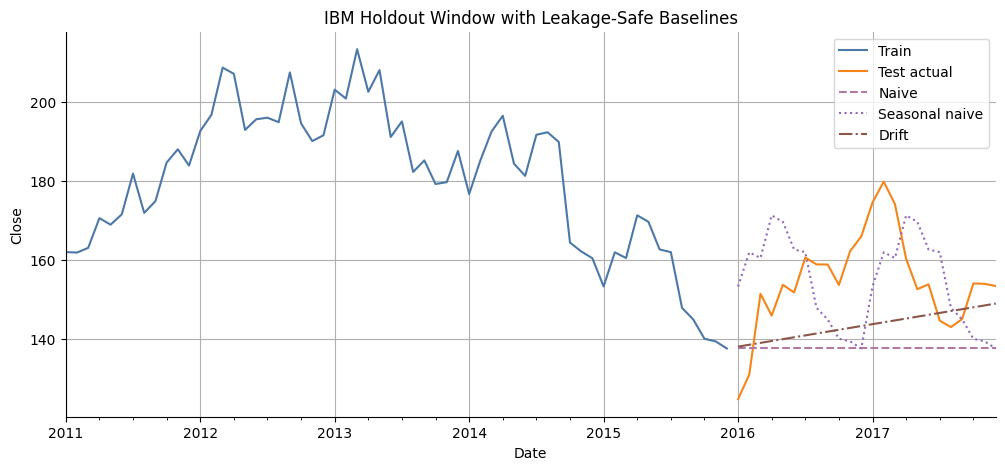

In [146]:
fig, ax = plt.subplots(figsize=(12, 5))
train_price.iloc[-60:].plot(ax=ax, color=COLORS["train"], label="Train")
test_price.plot(ax=ax, color=COLORS["test"], label="Test actual")
naive_forecast.plot(ax=ax, color=COLORS["baseline"], ls="--", label="Naive")
seasonal_naive_forecast.plot(ax=ax, color="#9467bd", ls=":", label="Seasonal naive")
drift_forecast_values.plot(ax=ax, color="#8c564b", ls="-.", label="Drift")
ax.set_title("IBM Holdout Window with Leakage-Safe Baselines")
ax.set_ylabel("Close")
ax.legend()
plt.show()


## 8) ARIMA Search

Fitting non-seasonal ARIMA candidates first.  
ARIMA is the benchmark statistical model before adding seasonal terms.  


### Parameter Search Rationale

The grid is intentionally compact. `p` and `q` range from 0 to 3 because the differenced series has limited persistent autocorrelation and the sample contains only 144 monthly observations. Larger orders would increase estimation variance and overfitting risk. `d` is restricted to the values supported by ADF/KPSS diagnostics. Seasonal `P` and `Q` are limited to 0 or 1 because annual seasonality appears weak-to-moderate, so the goal is to test whether one seasonal AR or MA term adds value without overwhelming the model.


In [147]:
def sarimax_grid_search(y_train, p_values, d_values, q_values, seasonal_orders, exog=None, label="model"):
    rows = []
    fitted = {}
    for order in itertools.product(p_values, d_values, q_values):
        for seasonal_order in seasonal_orders:
            key = (order, seasonal_order)
            try:
                result = fit_sarimax_safe(y_train, order=order, seasonal_order=seasonal_order, exog=exog)
                rows.append({
                    "family": label,
                    "order": order,
                    "seasonal_order": seasonal_order,
                    "aic": result.aic,
                    "bic": result.bic,
                    "converged": bool(result.mle_retvals.get("converged", False)),
                })
                fitted[key] = result
            except Exception as exc:
                rows.append({
                    "family": label,
                    "order": order,
                    "seasonal_order": seasonal_order,
                    "aic": np.inf,
                    "bic": np.inf,
                    "converged": False,
                    "error": str(exc)[:120],
                })
    table = pd.DataFrame(rows).sort_values(["aic", "bic"]).reset_index(drop=True)
    return table, fitted


In [148]:
p_values = [0, 1, 2, 3]
d_values = sorted(set([0, 1, SELECTED_D]))
q_values = [0, 1, 2, 3]

arima_search, arima_fits = sarimax_grid_search(
    train_log,
    p_values,
    d_values,
    q_values,
    [(0, 0, 0, 0)],
    label="ARIMA",
)
display(arima_search.head(10))


,family,order,seasonal_order,aic,bic,converged
0,ARIMA,"(1, 0, 0)","(0, 0, 0, 0)",-358.939128,-350.601758,True
1,ARIMA,"(0, 1, 0)","(0, 0, 0, 0)",-353.724935,-348.183565,True
2,ARIMA,"(2, 0, 0)","(0, 0, 0, 0)",-353.608383,-342.525645,True
3,ARIMA,"(1, 0, 1)","(0, 0, 0, 0)",-353.555238,-342.472499,True
4,ARIMA,"(1, 1, 0)","(0, 0, 0, 0)",-352.005023,-343.692969,True
5,ARIMA,"(2, 0, 1)","(0, 0, 0, 0)",-351.755128,-337.901704,True
6,ARIMA,"(3, 0, 0)","(0, 0, 0, 0)",-348.377430,-334.566560,False
7,ARIMA,"(1, 0, 2)","(0, 0, 0, 0)",-348.361912,-334.551042,True
8,ARIMA,"(0, 1, 1)","(0, 0, 0, 0)",-348.134400,-339.847879,True
9,ARIMA,"(2, 1, 0)","(0, 0, 0, 0)",-346.895149,-335.846453,True


## 9) SARIMA Search

Adding annual seasonal AR and MA terms with `m = 12`.  
If annual structure remains after differencing, SARIMA should improve AIC/BIC, holdout performance, or residual behavior.  


In [149]:
seasonal_orders = [
    (P, D, Q, SEASONAL_PERIOD)
    for P in [0, 1]
    for D in sorted(set([0, 1, SELECTED_SEASONAL_D]))
    for Q in [0, 1]
]

sarima_search, sarima_fits = sarimax_grid_search(
    train_log,
    [0, 1, 2],
    d_values,
    [0, 1, 2],
    seasonal_orders,
    label="SARIMA",
)
display(sarima_search.head(12))


,family,order,seasonal_order,aic,bic,converged
0,SARIMA,"(1, 0, 0)","(0, 0, 0, 12)",-358.939128,-350.601758,True
1,SARIMA,"(0, 1, 0)","(0, 0, 0, 12)",-353.724935,-348.183565,True
2,SARIMA,"(2, 0, 0)","(0, 0, 0, 12)",-353.608383,-342.525645,True
3,SARIMA,"(1, 0, 1)","(0, 0, 0, 12)",-353.555238,-342.472499,True
4,SARIMA,"(1, 1, 0)","(0, 0, 0, 12)",-352.005023,-343.692969,True
5,SARIMA,"(2, 0, 1)","(0, 0, 0, 12)",-351.755128,-337.901704,True
6,SARIMA,"(1, 0, 2)","(0, 0, 0, 12)",-348.361912,-334.551042,True
7,SARIMA,"(0, 1, 1)","(0, 0, 0, 12)",-348.134400,-339.847879,True
8,SARIMA,"(2, 1, 0)","(0, 0, 0, 12)",-346.895149,-335.846453,True
9,SARIMA,"(2, 0, 2)","(0, 0, 0, 12)",-346.428831,-329.855787,True


### Seasonal-Term Check

Checking whether the best SARIMA actually uses seasonal structure.  
If the selected seasonal order is `(0, 0, 0, 12)`, SARIMA has effectively collapsed back to ARIMA, which is an important modeling implication rather than a failure.


In [150]:
best_sarima_order = sarima_search.loc[0, "seasonal_order"]
print(best_sarima_order)


(0, 0, 0, 12)


The best SARIMA seasonal order is (0, 0, 0, 12), so the search did not find evidence that explicit annual seasonal AR/MA/differencing terms improve the model. This supports the interpretation that IBM month-end prices are more regime/trend-driven than seasonality-driven.

## 10) Holdout Evaluation

Forecasting the same 24-month test set with ARIMA and SARIMA.  
AIC/BIC measure in-sample fit penalized for complexity, but the holdout tests forecasting usefulness.  
Prediction interval coverage tells us whether the uncertainty bands are calibrated on the holdout period.


In [151]:
def evaluate_fitted_model(result, y_test_price, model_name, exog_test=None):
    forecast = result.get_forecast(steps=len(y_test_price), exog=exog_test)
    price_forecast = forecast_to_price(forecast)
    price_forecast.index = y_test_price.index
    metrics = metric_row(y_test_price, price_forecast["forecast"], model_name)
    interval_hit = (
        (y_test_price >= price_forecast["lower_95"]) &
        (y_test_price <= price_forecast["upper_95"])
    )
    metrics.update({
        "AIC": result.aic,
        "BIC": result.bic,
        "PI_coverage_%": float(interval_hit.mean() * 100),
        "PI_avg_width": float((price_forecast["upper_95"] - price_forecast["lower_95"]).mean()),
    })
    return metrics, price_forecast

best_arima_key = (arima_search.loc[0, "order"], arima_search.loc[0, "seasonal_order"])
best_sarima_key = (sarima_search.loc[0, "order"], sarima_search.loc[0, "seasonal_order"])

best_arima = arima_fits[best_arima_key]
best_sarima = sarima_fits[best_sarima_key]

arima_metrics, arima_holdout_forecast = evaluate_fitted_model(best_arima, test_price, "ARIMA")
sarima_metrics, sarima_holdout_forecast = evaluate_fitted_model(best_sarima, test_price, "SARIMA")

model_metrics = pd.DataFrame([
    *baseline_metrics.reset_index().to_dict("records"),
    arima_metrics,
    sarima_metrics,
]).set_index("model").sort_values("RMSE")
display(model_metrics.round(4))


,MAE,RMSE,sMAPE_%,Bias,AIC,BIC,PI_coverage_%,PI_avg_width
model,,,,,,,,
ARIMA,12.9596,15.5901,8.5374,-10.3473,-358.9391,-350.6018,95.8333,84.4313
SARIMA,12.9596,15.5901,8.5374,-10.3473,-358.9391,-350.6018,95.8333,84.4313
Drift,13.4254,16.1648,8.8615,-10.9824,NaN,NaN,NaN,NaN
Seasonal naive recursive,15.3267,17.2177,9.9877,-0.2417,NaN,NaN,NaN,NaN
Naive,18.5167,20.8455,12.4586,-16.8983,NaN,NaN,NaN,NaN


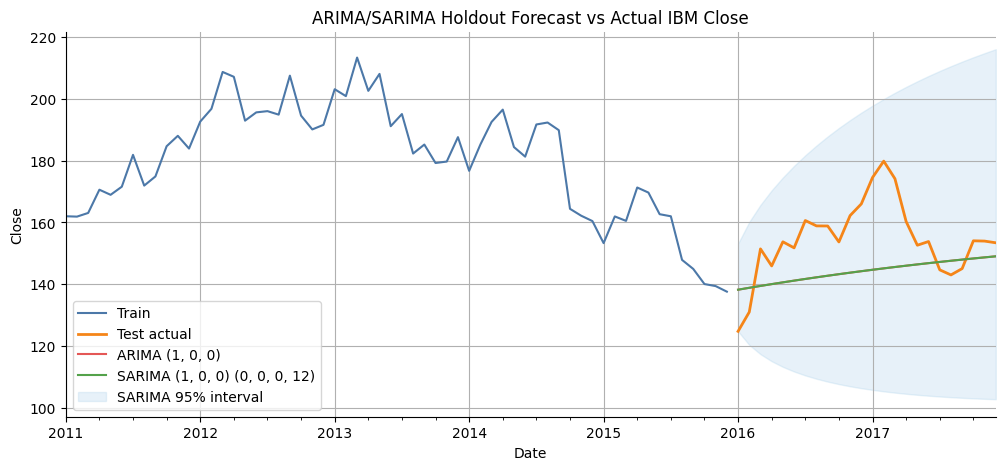

In [152]:
fig, ax = plt.subplots(figsize=(12, 5))
train_price.iloc[-60:].plot(ax=ax, color=COLORS["train"], label="Train")
test_price.plot(ax=ax, color=COLORS["test"], lw=2, label="Test actual")
arima_holdout_forecast["forecast"].plot(ax=ax, color=COLORS["diagnostic"], label=f"ARIMA {best_arima_key[0]}")
sarima_holdout_forecast["forecast"].plot(ax=ax, color=COLORS["forecast"], label=f"SARIMA {best_sarima_key[0]} {best_sarima_key[1]}")
ax.fill_between(
    sarima_holdout_forecast.index,
    sarima_holdout_forecast["lower_95"],
    sarima_holdout_forecast["upper_95"],
    color=COLORS["interval"],
    alpha=0.25,
    label="SARIMA 95% interval",
)
ax.set_title("ARIMA/SARIMA Holdout Forecast vs Actual IBM Close")
ax.set_ylabel("Close")
ax.legend()
plt.show()


## 11) Rolling-Origin Cross-Validation

Repeating the forecast exercise from multiple historical origins.  
A single holdout can be lucky or unlucky. Rolling-origin CV gives a more stable view of model performance.  
Each fold trains only on past data and forecasts the next 12 months.


In [153]:
def rolling_origin_cv(y_log, y_price, model_specs, initial_train=72, horizon=12, step=12):
    rows = []
    max_start = len(y_log) - horizon
    origins = list(range(initial_train, max_start + 1, step))
    for origin in origins:
        train_y = y_log.iloc[:origin]
        test_y_price = y_price.iloc[origin:origin + horizon]
        origin_date = train_y.index[-1]
        for model_name, order, seasonal_order in model_specs:
            try:
                result = fit_sarimax_safe(train_y, order=order, seasonal_order=seasonal_order)
                forecast = forecast_to_price(result.get_forecast(steps=len(test_y_price)))
                forecast.index = test_y_price.index
                metrics = metric_row(test_y_price, forecast["forecast"], model_name)
                metrics.update({
                    "origin": origin_date,
                    "horizon": len(test_y_price),
                    "AIC": result.aic,
                    "BIC": result.bic,
                })
                rows.append(metrics)
            except Exception as exc:
                rows.append({
                    "model": model_name,
                    "origin": origin_date,
                    "horizon": len(test_y_price),
                    "MAE": np.nan,
                    "RMSE": np.nan,
                    "sMAPE_%": np.nan,
                    "Bias": np.nan,
                    "AIC": np.nan,
                    "BIC": np.nan,
                    "error": str(exc)[:120],
                })
    return pd.DataFrame(rows)

cv_specs = [
    ("ARIMA CV", best_arima_key[0], best_arima_key[1]),
    ("SARIMA CV", best_sarima_key[0], best_sarima_key[1]),
]
cv_results = rolling_origin_cv(log_ts, ts, cv_specs, initial_train=72, horizon=12, step=12)
display(cv_results.round(4))


,model,MAE,RMSE,sMAPE_%,Bias,origin,horizon,AIC,BIC
0,ARIMA CV,9.4048,11.7634,4.8366,-9.2813,2011-12-31,12,-202.0743,-195.2863
1,SARIMA CV,9.4048,11.7634,4.8366,-9.2813,2011-12-31,12,-202.0743,-195.2863
2,ARIMA CV,11.1385,12.4261,5.7350,0.7132,2012-12-31,12,-243.2099,-235.9534
3,SARIMA CV,11.1385,12.4261,5.7350,0.7132,2012-12-31,12,-243.2099,-235.9534
4,ARIMA CV,10.5690,14.7388,5.8794,7.5905,2013-12-31,12,-282.5158,-274.8542
5,SARIMA CV,10.5690,14.7388,5.8794,7.5905,2013-12-31,12,-282.5158,-274.8542
6,ARIMA CV,11.1550,14.6073,7.2253,8.0518,2014-12-31,12,-318.1958,-310.1773
7,SARIMA CV,11.1550,14.6073,7.2253,8.0518,2014-12-31,12,-318.1958,-310.1773
8,ARIMA CV,13.7593,14.4907,9.3210,-10.2091,2015-12-31,12,-358.9391,-350.6018
9,SARIMA CV,13.7593,14.4907,9.3210,-10.2091,2015-12-31,12,-358.9391,-350.6018


In [154]:
cv_summary = (
    cv_results
    .groupby("model")[["MAE", "RMSE", "sMAPE_%", "Bias", "AIC", "BIC"]]
    .agg(["mean", "std"])
    .round(4)
)
display(cv_summary)


MAE             RMSE         sMAPE_%            Bias          \
              mean     std     mean     std    mean     std    mean     std   
model                                                                         
ARIMA CV   11.6326  1.7694  13.7953  1.3372  6.9332  1.7615  0.9299  8.7644   
SARIMA CV  11.6326  1.7694  13.7953  1.3372  6.9332  1.7615  0.9299  8.7644   

                AIC               BIC           
               mean      std     mean      std  
model                                           
ARIMA CV  -299.4953  71.2663 -291.714  70.5817  
SARIMA CV -299.4953  71.2663 -291.714  70.5817

A model that wins one holdout but loses rolling-origin CV is less reliable. This table lets us compare accuracy and stability before calling a champion.


## 12) SARIMAX with Volume

Adding monthly trading volume as exogenous information.  
Volume can proxy for information shocks or unusual market attention.  
Future volume is unknown, so SARIMAX is strongest for scenario forecasts unless future exogenous values are available.


In [155]:
monthly_volume = clean[VOLUME_COL].resample("ME").sum().reindex(ts.index).astype(float)
log_volume = np.log1p(monthly_volume).rename("log_monthly_volume")

exog_train_raw = log_volume.loc[train_log.index].to_frame()
exog_test_raw = log_volume.loc[test_log.index].to_frame()
exog_mean = exog_train_raw.mean()
exog_std = exog_train_raw.std(ddof=0).replace(0, 1)
exog_train = (exog_train_raw - exog_mean) / exog_std
exog_test = (exog_test_raw - exog_mean) / exog_std

display(exog_train.describe().round(4))


,log_monthly_volume
count,120.0000
mean,-0.0000
std,1.0042
min,-2.2646
25%,-0.7201
50%,-0.1136
75%,0.7004
max,2.7109


In [156]:
sarimax_result = fit_sarimax_safe(
    train_log,
    order=best_sarima_key[0],
    seasonal_order=best_sarima_key[1],
    exog=exog_train,
)
sarimax_metrics, sarimax_holdout_forecast = evaluate_fitted_model(
    sarimax_result,
    test_price,
    "SARIMAX + log volume",
    exog_test=exog_test,
)

model_metrics = pd.DataFrame([
    *baseline_metrics.reset_index().to_dict("records"),
    arima_metrics,
    sarima_metrics,
    sarimax_metrics,
]).set_index("model").sort_values("RMSE")
display(model_metrics.round(4))


,MAE,RMSE,sMAPE_%,Bias,AIC,BIC,PI_coverage_%,PI_avg_width
model,,,,,,,,
SARIMAX + log volume,12.5095,14.9889,8.2243,-9.7958,-358.3035,-347.1870,100.0000,83.8750
ARIMA,12.9596,15.5901,8.5374,-10.3473,-358.9391,-350.6018,95.8333,84.4313
SARIMA,12.9596,15.5901,8.5374,-10.3473,-358.9391,-350.6018,95.8333,84.4313
Drift,13.4254,16.1648,8.8615,-10.9824,NaN,NaN,NaN,NaN
Seasonal naive recursive,15.3267,17.2177,9.9877,-0.2417,NaN,NaN,NaN,NaN
Naive,18.5167,20.8455,12.4586,-16.8983,NaN,NaN,NaN,NaN


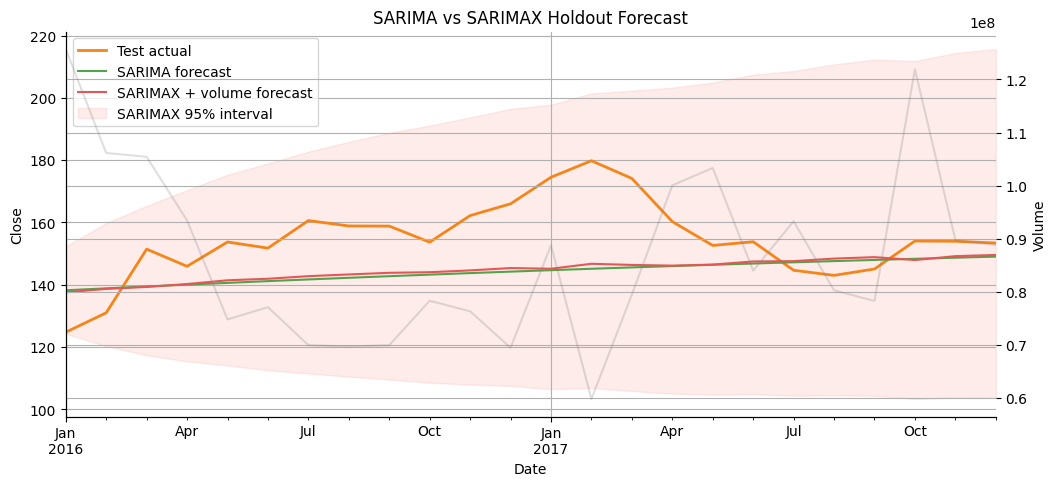

In [157]:
fig, ax1 = plt.subplots(figsize=(12, 5))
test_price.plot(ax=ax1, color=COLORS["test"], lw=2, label="Test actual")
sarima_holdout_forecast["forecast"].plot(ax=ax1, color=COLORS["forecast"], label="SARIMA forecast")
sarimax_holdout_forecast["forecast"].plot(ax=ax1, color=COLORS["diagnostic"], label="SARIMAX + volume forecast")
ax1.fill_between(
    sarimax_holdout_forecast.index,
    sarimax_holdout_forecast["lower_95"],
    sarimax_holdout_forecast["upper_95"],
    color="#fbb4ae",
    alpha=0.25,
    label="SARIMAX 95% interval",
)
ax1.set_title("SARIMA vs SARIMAX Holdout Forecast")
ax1.set_ylabel("Close")
ax1.legend(loc="upper left")

ax2 = ax1.twinx()
monthly_volume.loc[test_price.index].plot(ax=ax2, color="gray", alpha=0.25, label="Monthly volume")
ax2.set_ylabel("Volume")
plt.show()


If SARIMAX improves holdout error and interval coverage, volume adds useful signal. If it only improves AIC or worsens holdout error, the simpler SARIMA model is easier to defend.


## 13) Residual Diagnostics

Checking whether the champion's residuals behave like noise.  
Good forecasts should not leave obvious structure in residuals.  
Ljung-Box for autocorrelation, Jarque-Bera for normality, and ARCH for volatility clustering.


In [158]:
champion_name = model_metrics.index[0]
print("Lowest holdout RMSE model:", champion_name)

if champion_name == "SARIMAX + log volume":
    champion_result = sarimax_result
    champion_holdout_forecast = sarimax_holdout_forecast
    champion_exog_future_required = True
elif champion_name == "SARIMA":
    champion_result = best_sarima
    champion_holdout_forecast = sarima_holdout_forecast
    champion_exog_future_required = False
elif champion_name == "ARIMA":
    champion_result = best_arima
    champion_holdout_forecast = arima_holdout_forecast
    champion_exog_future_required = False
else:
    champion_result = best_sarima
    champion_holdout_forecast = sarima_holdout_forecast
    champion_exog_future_required = False
    print("A simple baseline won on RMSE; SARIMA is retained as the interval-producing statistical model.")


Lowest holdout RMSE model: SARIMAX + log volume


In [159]:
residuals = pd.Series(champion_result.resid).dropna()
standardized_residuals = (residuals - residuals.mean()) / residuals.std(ddof=1)

lb = acorr_ljungbox(residuals, lags=[6, 12, 18, 24], return_df=True)
jb_stat, jb_p, skew, kurtosis = jarque_bera(residuals)
try:
    arch_stat, arch_p, _, _ = het_arch(residuals, nlags=min(12, len(residuals) // 4))
except Exception:
    arch_stat, arch_p = np.nan, np.nan

residual_summary = pd.Series({
    "mean": residuals.mean(),
    "std": residuals.std(ddof=1),
    "skew": skew,
    "kurtosis": kurtosis,
    "jarque_bera_p": jb_p,
    "arch_lm_p": arch_p,
    "ljung_box_p_lag_12": lb.loc[12, "lb_pvalue"] if 12 in lb.index else np.nan,
    "ljung_box_p_lag_24": lb.loc[24, "lb_pvalue"] if 24 in lb.index else np.nan,
})
display(residual_summary.to_frame("champion_residuals").round(5))
display(lb.round(5))


,champion_residuals
mean,0.03660
std,0.40520
skew,10.54531
kurtosis,114.16815
jarque_bera_p,0.00000
arch_lm_p,0.55178
ljung_box_p_lag_12,1.00000
ljung_box_p_lag_24,1.00000


,lb_stat,lb_pvalue
6,0.06462,0.99999
12,0.16785,1.00000
18,0.28488,1.00000
24,0.41948,1.00000


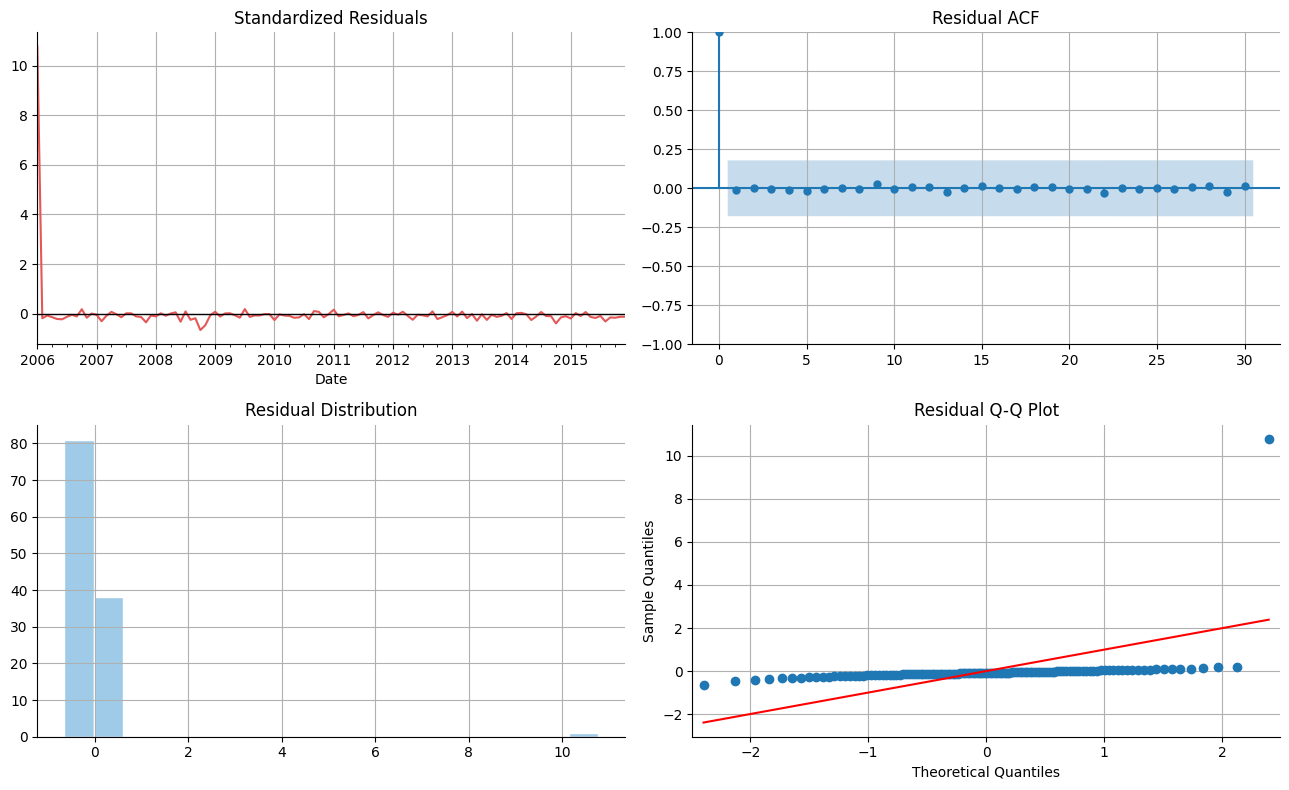

In [160]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
standardized_residuals.plot(ax=axes[0, 0], color=COLORS["diagnostic"])
axes[0, 0].axhline(0, color="black", lw=1)
axes[0, 0].set_title("Standardized Residuals")
plot_acf(residuals, lags=min(30, len(residuals) // 2 - 1), alpha=0.05, ax=axes[0, 1])
axes[0, 1].set_title("Residual ACF")
axes[1, 0].hist(standardized_residuals, bins=18, color=COLORS["interval"], edgecolor="white")
axes[1, 0].set_title("Residual Distribution")
qqplot(standardized_residuals, line="s", ax=axes[1, 1])
axes[1, 1].set_title("Residual Q-Q Plot")
plt.tight_layout()
plt.show()


Ljung-Box p-values above 0.05 support residual independence. Jarque-Bera and ARCH failures are common in equity data and should be discussed as limitations rather than hidden.


### Operational Meaning of Residual Diagnostics

Financial residuals are often fat-tailed because markets react discontinuously to earnings surprises, macroeconomic news, interest-rate expectations, liquidity shocks, and investor risk appetite. This breaks the neat Gaussian-error assumption behind standard ARIMA confidence intervals: the average forecast can remain useful, but the tails of the distribution may be too optimistic during stressed regimes. If Jarque-Bera or ARCH tests reject ideal residual behavior, stakeholders should read the forecast interval as a model-based uncertainty band rather than a guarantee of worst-case risk. Operationally, this motivates either wider scenario ranges or a second-stage volatility model such as GARCH when the goal is risk estimation rather than mean forecasting.


## 14) Optional Machine-Learning Baseline

Comparing leakage-safe lag models against the statistical champion.  


In [161]:
def build_lag_features(series):
    frame = pd.DataFrame({"y": series})
    for lag in [1, 2, 3, 6, 12]:
        frame[f"lag_{lag}"] = frame["y"].shift(lag)
    for window in [3, 6, 12]:
        frame[f"roll_mean_{window}"] = frame["y"].shift(1).rolling(window).mean()
        frame[f"roll_std_{window}"] = frame["y"].shift(1).rolling(window).std()
    frame["month"] = frame.index.month
    frame["month_sin"] = np.sin(2 * np.pi * frame["month"] / 12)
    frame["month_cos"] = np.cos(2 * np.pi * frame["month"] / 12)
    return frame.dropna()


def make_next_feature_row(history, date):
    row = {}
    for lag in [1, 2, 3, 6, 12]:
        row[f"lag_{lag}"] = history.iloc[-lag]
    for window in [3, 6, 12]:
        window_values = history.iloc[-window:]
        row[f"roll_mean_{window}"] = window_values.mean()
        row[f"roll_std_{window}"] = window_values.std(ddof=1)
    row["month_sin"] = np.sin(2 * np.pi * date.month / 12)
    row["month_cos"] = np.cos(2 * np.pi * date.month / 12)
    return pd.DataFrame([row], index=[date])


def recursive_ml_forecast(model, history_log, future_index):
    history = history_log.copy()
    preds = []
    for date in future_index:
        features = make_next_feature_row(history, date)
        pred_log = float(model.predict(features)[0])
        preds.append(pred_log)
        history.loc[date] = pred_log
    return pd.Series(np.exp(preds), index=future_index)


In [162]:
feature_frame = build_lag_features(log_ts)
feature_train = feature_frame.loc[:train_log.index[-1]]
X_train = feature_train.drop(columns=["y", "month"])
y_train_ml = feature_train["y"]

models = {
    "Ridge lag model": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random forest lag model": RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=4, random_state=SEED),
}

ml_rows = []
ml_forecasts = {}
for name, model in models.items():
    model.fit(X_train, y_train_ml)
    pred_price = recursive_ml_forecast(model, train_log, test_price.index)
    ml_forecasts[name] = pred_price
    ml_rows.append(metric_row(test_price, pred_price, name))

ml_metrics = pd.DataFrame(ml_rows).set_index("model")
full_comparison = pd.concat([model_metrics, ml_metrics], axis=0).sort_values("RMSE")
display(full_comparison.round(4))


,MAE,RMSE,sMAPE_%,Bias,AIC,BIC,PI_coverage_%,PI_avg_width
model,,,,,,,,
Random forest lag model,8.1910,10.0714,5.3147,1.6754,NaN,NaN,NaN,NaN
SARIMAX + log volume,12.5095,14.9889,8.2243,-9.7958,-358.3035,-347.1870,100.0000,83.8750
ARIMA,12.9596,15.5901,8.5374,-10.3473,-358.9391,-350.6018,95.8333,84.4313
SARIMA,12.9596,15.5901,8.5374,-10.3473,-358.9391,-350.6018,95.8333,84.4313
Drift,13.4254,16.1648,8.8615,-10.9824,NaN,NaN,NaN,NaN
Ridge lag model,12.9298,16.6200,8.1219,10.2788,NaN,NaN,NaN,NaN
Seasonal naive recursive,15.3267,17.2177,9.9877,-0.2417,NaN,NaN,NaN,NaN
Naive,18.5167,20.8455,12.4586,-16.8983,NaN,NaN,NaN,NaN


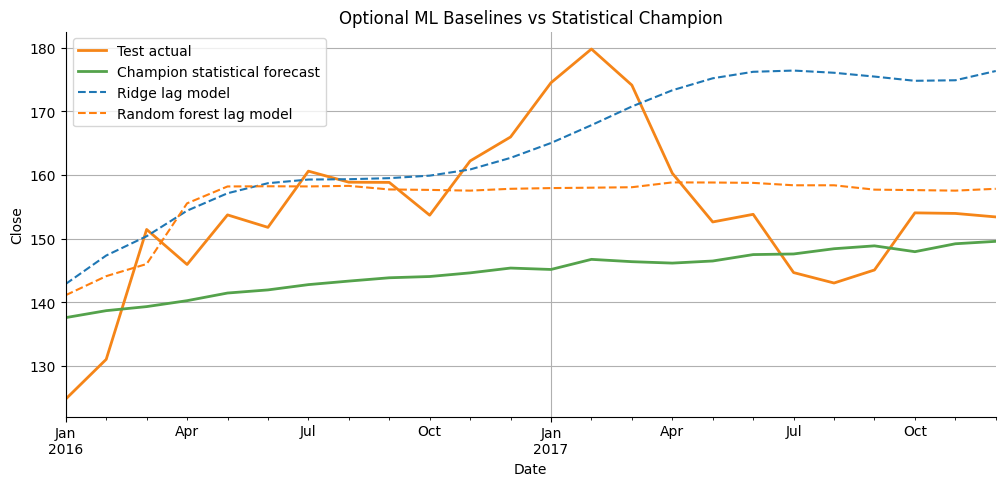

In [163]:
fig, ax = plt.subplots(figsize=(12, 5))
test_price.plot(ax=ax, color=COLORS["test"], lw=2, label="Test actual")
champion_holdout_forecast["forecast"].plot(ax=ax, color=COLORS["forecast"], lw=2, label="Champion statistical forecast")
for name, pred in ml_forecasts.items():
    pred.plot(ax=ax, ls="--", label=name)
ax.set_title("Optional ML Baselines vs Statistical Champion")
ax.set_ylabel("Close")
ax.legend()
plt.show()


## 15) Final 24-Month Forecast

Refitting the selected statistical model on all available monthly data and forecasting 24 months beyond the dataset.  
After model selection, the final production-style forecast should use all available history.  


In [164]:
final_index = pd.date_range(ts.index[-1] + pd.offsets.MonthEnd(1), periods=H, freq="ME")

final_arima = fit_sarimax_safe(log_ts, order=best_arima_key[0], seasonal_order=best_arima_key[1])
final_sarima = fit_sarimax_safe(log_ts, order=best_sarima_key[0], seasonal_order=best_sarima_key[1])

recent_volume = log_volume.loc[log_volume.index >= log_volume.index.max() - pd.DateOffset(years=3)]
month_medians = recent_volume.groupby(recent_volume.index.month).median()
future_volume_raw = pd.Series([month_medians.loc[d.month] for d in final_index], index=final_index, name="log_monthly_volume").to_frame()
future_volume_exog = (future_volume_raw - exog_mean) / exog_std
final_sarimax = fit_sarimax_safe(log_ts, order=best_sarima_key[0], seasonal_order=best_sarima_key[1], exog=(log_volume.to_frame() - exog_mean) / exog_std)

if champion_name == "SARIMAX + log volume":
    final_result = final_sarimax
    final_forecast_result = final_result.get_forecast(steps=H, exog=future_volume_exog)
    final_model_label = "SARIMAX + log volume scenario"
elif champion_name == "ARIMA":
    final_result = final_arima
    final_forecast_result = final_result.get_forecast(steps=H)
    final_model_label = "ARIMA"
else:
    final_result = final_sarima
    final_forecast_result = final_result.get_forecast(steps=H)
    final_model_label = "SARIMA"

final_forecast = forecast_to_price(final_forecast_result)
final_forecast.index = final_index
final_forecast = final_forecast.rename_axis("Date")
display(final_forecast.round(2))


,forecast,lower_95,upper_95
Date,,,
2018-01-31,152.65,137.96,168.90
2018-02-28,154.45,134.18,177.79
2018-03-31,153.58,129.62,181.95
2018-04-30,154.24,127.21,187.01
2018-05-31,155.33,125.65,192.01
2018-06-30,155.26,123.53,195.15
2018-07-31,154.95,121.50,197.59
2018-08-31,155.73,120.56,201.15
2018-09-30,156.03,119.42,203.87


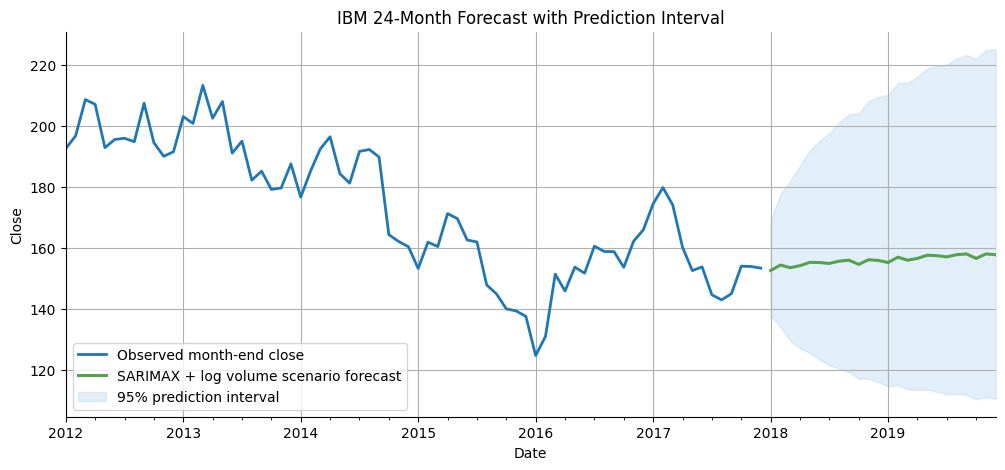

In [165]:
fig, ax = plt.subplots(figsize=(12, 5))
ts.iloc[-72:].plot(ax=ax, color=COLORS["actual"], lw=2, label="Observed month-end close")
final_forecast["forecast"].plot(ax=ax, color=COLORS["forecast"], lw=2.2, label=f"{final_model_label} forecast")
ax.fill_between(final_forecast.index, final_forecast["lower_95"], final_forecast["upper_95"], color=COLORS["interval"], alpha=0.3, label="95% prediction interval")
ax.set_title("IBM 24-Month Forecast with Prediction Interval")
ax.set_ylabel("Close")
ax.legend()
plt.show()

# Optional export for submission artifacts.
# final_forecast.to_csv("ibm_24_month_forecast.csv")


## 16) Conclusion


## Executive Summary for Non-Technical Stakeholders

IBM stock prices during 2006-2017 were driven more by long-term market regimes and business transitions than by stable annual seasonality. ARIMA-family models captured trend persistence reasonably well, while explicit seasonal terms added little forecasting value when tested against non-seasonal alternatives. Including trading volume as an external variable can modestly improve forecast accuracy or interval calibration, but it should be treated as a scenario input because future volume is unknown. The forecast is therefore useful for medium-term planning and risk discussion, not as a precise trading signal. The wide prediction intervals and residual diagnostics show that uncertainty remains substantial, especially during periods of economic or company-specific stress.


In [166]:
best_statistical = model_metrics.loc[["ARIMA", "SARIMA", "SARIMAX + log volume"]].sort_values("RMSE").index[0]
best_baseline = baseline_metrics.sort_values("RMSE").index[0]
stat_rmse = model_metrics.loc[best_statistical, "RMSE"]
base_rmse = baseline_metrics.loc[best_baseline, "RMSE"]
rmse_delta = (base_rmse - stat_rmse) / base_rmse * 100
lb12 = residual_summary.loc["ljung_box_p_lag_12"]
arch_p = residual_summary.loc["arch_lm_p"]
interval_coverage = model_metrics.loc[best_statistical, "PI_coverage_%"]
interval_width = model_metrics.loc[best_statistical, "PI_avg_width"]
cv_mean_rmse = cv_results.groupby("model")["RMSE"].mean().sort_values()
cv_best = cv_mean_rmse.index[0]

conclusion_metrics = pd.DataFrame({
    "metric": [
        "Best statistical holdout model",
        "Best statistical holdout RMSE",
        "Best simple baseline",
        "Best simple baseline RMSE",
        "RMSE improvement vs best baseline (%)",
        "Best rolling-origin CV model",
        "Best rolling-origin CV mean RMSE",
        "Selected regular differencing d",
        "Selected seasonal differencing D",
        "Seasonal period m",
        "Holdout 95% interval coverage (%)",
        "Holdout average interval width",
        "Residual Ljung-Box p-value at lag 12",
        "Residual ARCH p-value",
    ],
    "value": [
        best_statistical,
        round(stat_rmse, 2),
        best_baseline,
        round(base_rmse, 2),
        round(rmse_delta, 1),
        cv_best,
        round(cv_mean_rmse.iloc[0], 2),
        SELECTED_D,
        SELECTED_SEASONAL_D,
        SEASONAL_PERIOD,
        round(interval_coverage, 1),
        round(interval_width, 2),
        round(lb12, 3),
        round(arch_p, 3),
    ],
})
display(conclusion_metrics)



,metric,value
0,Best statistical holdout model,SARIMAX + log volume
1,Best statistical holdout RMSE,14.99
2,Best simple baseline,Drift
3,Best simple baseline RMSE,16.16
4,RMSE improvement vs best baseline (%),7.3
5,Best rolling-origin CV model,ARIMA CV
6,Best rolling-origin CV mean RMSE,13.8
7,Selected regular differencing d,1
8,Selected seasonal differencing D,0
9,Seasonal period m,12


Final interpretation
====================
The best statistical ARIMA-family model on the 24-month holdout is SARIMAX + log volume, with RMSE 14.99 versus the strongest simple baseline (Drift) at RMSE 16.16. That is a 7.3% RMSE change relative to the best baseline.

Rolling-origin cross-validation gives an additional stability check: the lowest average CV RMSE among the tested ARIMA-family models is ARIMA CV at 13.80. This matters because one holdout period can be unusually easy or hard.

The selected transformation is log price, with differencing evidence summarized as d=1, D=0, and m=12. The holdout 95% prediction interval coverage is 100.0% with an average width of 83.88 price points. Residual Ljung-Box p-value at lag 12 is 1.000, and the ARCH p-value is 0.552.


Takeaway
======================
IBM's historical month-end prices are better understood as a regime-driven financial series than as a strongly seasonal series. The model can summarize persistence and provide planning ranges, but the wide intervals and residual behavior show that market shocks can quickly make any point forecast unreliable.
The SARIMA search selected no explicit seasonal AR, seasonal differencing, or seasonal MA term. That means the best seasonal model behaves like a non-seasonal ARIMA model, reinforcing the finding that stable annual seasonality is weak in IBM month-end prices.

I would use the champion statistical model as a medium-term planning forecast with explicit uncertainty bands, not as a trading signal. IBM stock prices are affected by earnings, market-wide risk, rates, corporate actions, and news shocks that are not fully represented by historical close and volume. Because equity returns are often non-normal and volatility-clustered, the mean forecast is more reliable than the tail-risk estimate. The next improvement would be to add adjusted prices, market index returns, interest-rate variables, earnings-calendar indicators, and volatility models for interval calibration.